In [1]:
# ---
# title: Explore Lit2Vec TL;DR Dataset
# author: Bocklitz Lab
# date: 2025-08-21
# description: Explore dataset splits, fields, licensing, and example records.
# ---

# ## 1. Setup

from datasets import load_dataset
import pandas as pd

DATASET_ID = "Bocklitz-Lab/lit2vec-tldr-bart-dataset"

# Prefer the modern `token=` param; fall back to use_auth_token if your version needs it.
try:
    ds = load_dataset(
        DATASET_ID,
        split=None,                # get all splits if defined
        token=True,                # uses your cached HF login
        revision="main",           # avoid refs/convert/parquet unless we ask for it
        cache_dir="./.hf_cache_fresh",
        download_mode="force_redownload",
    )
except TypeError:
    # Older versions
    ds = load_dataset(
        DATASET_ID,
        split=None,
        use_auth_token=True,
        revision="main",
        cache_dir="./.hf_cache_fresh",
        download_mode="force_redownload",
    )
ds


/home/lit2vec-tldr-bart/myenv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Generating test split: 100%|██████████| 1001/1001 [00:00<00:00, 122745.16 examples/s]


DatasetDict({
    train: Dataset({
        features: ['corpus_id', 'doi', 'title', 'authors', 'venue', 'year', 'fields_of_study', 'publication_date', 'abstract', 'summary', 'license_type', 'license_publisher', 'license_url', 'source_url'],
        num_rows: 17992
    })
    validation: Dataset({
        features: ['corpus_id', 'doi', 'title', 'authors', 'venue', 'year', 'fields_of_study', 'publication_date', 'abstract', 'summary', 'license_type', 'license_publisher', 'license_url', 'source_url'],
        num_rows: 999
    })
    test: Dataset({
        features: ['corpus_id', 'doi', 'title', 'authors', 'venue', 'year', 'fields_of_study', 'publication_date', 'abstract', 'summary', 'license_type', 'license_publisher', 'license_url', 'source_url'],
        num_rows: 1001
    })
})

In [2]:
# ## 2. Basic statistics

print("Splits:", ds)
print("Train size:", len(ds["train"]))
print("Validation size:", len(ds["validation"]))
print("Test size:", len(ds["test"]))


Splits: DatasetDict({
    train: Dataset({
        features: ['corpus_id', 'doi', 'title', 'authors', 'venue', 'year', 'fields_of_study', 'publication_date', 'abstract', 'summary', 'license_type', 'license_publisher', 'license_url', 'source_url'],
        num_rows: 17992
    })
    validation: Dataset({
        features: ['corpus_id', 'doi', 'title', 'authors', 'venue', 'year', 'fields_of_study', 'publication_date', 'abstract', 'summary', 'license_type', 'license_publisher', 'license_url', 'source_url'],
        num_rows: 999
    })
    test: Dataset({
        features: ['corpus_id', 'doi', 'title', 'authors', 'venue', 'year', 'fields_of_study', 'publication_date', 'abstract', 'summary', 'license_type', 'license_publisher', 'license_url', 'source_url'],
        num_rows: 1001
    })
})
Train size: 17992
Validation size: 999
Test size: 1001


In [3]:
# ## 3. Inspect one example

example = ds["train"][0]
example


{'corpus_id': 250384325,
 'doi': '10.3390/biom12070947',
 'title': 'Diffusion of Vanadium Ions in Artificial Saliva and Its Elimination from the Oral Cavity by Pharmacological Compounds Present in Mouthwashes',
 'authors': ['Sónia I. G. Fangaia',
  'A. M. Cabral',
  'P. Nicolau',
  'Fernando Guerra',
  'M. Rodrigo',
  'A. C. Ribeiro',
  'A. Valente',
  'M. A. Esteso'],
 'venue': 'Biomolecules',
 'year': 2022,
 'fields_of_study': ['Chemistry', 'Medicine', 'Medicine'],
 'publication_date': datetime.datetime(2022, 7, 1, 0, 0),
 'abstract': 'In this study, diffusion coefficients of ammonium vanadate at tracer concentrations in artificial saliva with and without sodium fluoride, at different pH values, were measured using an experimental model based on the Taylor dispersion technique. Ternary mutual diffusion coefficients (D11, D22, D12, and D21) for four aqueous systems {NH4VO3 (component 1) + β-cyclodextrin (β-CD) (component 2),} {NH4VO3 (component 1) + β-cyclodextrin (HP-β-CD) (component

In [4]:
# ## 4. Convert to pandas for quick exploration

df_train = ds["train"].to_pandas()
df_train.head(3)


,corpus_id,doi,title,authors,venue,year,fields_of_study,publication_date,abstract,summary,license_type,license_publisher,license_url,source_url
0,250384325,10.3390/biom12070947,Diffusion of Vanadium Ions in Artificial Saliv...,"[Sónia I. G. Fangaia, A. M. Cabral, P. Nicolau...",Biomolecules,2022,"[Chemistry, Medicine, Medicine]",2022-07-01,"In this study, diffusion coefficients of ammon...",The study measured diffusion coefficients of a...,cc-by,MDPI AG,https://www.mdpi.com/2218-273X/12/7/947/pdf?ve...,https://www.semanticscholar.org/paper/1ca8e174...
1,252783771,10.3389/fpls.2022.991883,In situ detection of fruit spoilage based on v...,"[Yun-Qi Zhou, Yifan Gu, Rui Guo, L. Jiao, Ke W...",Frontiers in Plant Science,2022,"[Environmental Science, Chemistry, Medicine]",2022-10-11,Volatile compounds such as ethanol released fr...,A spiral silver halide FOEW sensor efficiently...,cc-by,Frontiers Media SA,https://www.frontiersin.org/articles/10.3389/f...,https://www.semanticscholar.org/paper/cbc732af...
2,221997392,10.1002/advs.202000843,A Rotating Spiral Micromotor for Noninvasive Z...,"[Lukas Schwarz, D. Karnaushenko, Franziska Heb...",Advancement of science,2020,"[Engineering, Medicine, Chemistry, Medicine]",2020-07-21,Embryo transfer (ET) is a decisive step in the...,This study demonstrates the use of magnetic mi...,cc-by,Wiley,https://onlinelibrary.wiley.com/doi/pdfdirect/...,https://www.semanticscholar.org/paper/a0ccdb76...



Abstract length (words) — stats
  count: 17992.00
  mean: 188.15
   std: 78.91
   min: 1.00
   10%: 95.00
   25%: 143.00
   50%: 189.00
   75%: 229.00
   90%: 274.00
   95%: 307.00
   max: 1539.00

Summary length (words) — stats
  count: 17992.00
  mean: 32.09
   std: 7.01
   min: 0.00
   10%: 24.00
   25%: 27.00
   50%: 32.00
   75%: 37.00
   90%: 41.00
   95%: 44.00
   max: 66.00

Summary/Abstract ratio (words) — stats
  count: 17992.00
  mean: 0.21
   std: 0.15
   min: 0.00
   10%: 0.12
   25%: 0.14
   50%: 0.17
   75%: 0.22
   90%: 0.30
   95%: 0.40
   max: 9.00


/tmp/ipykernel_302823/3705530743.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax3.set_xticklabels(["Abstract", "Summary"])


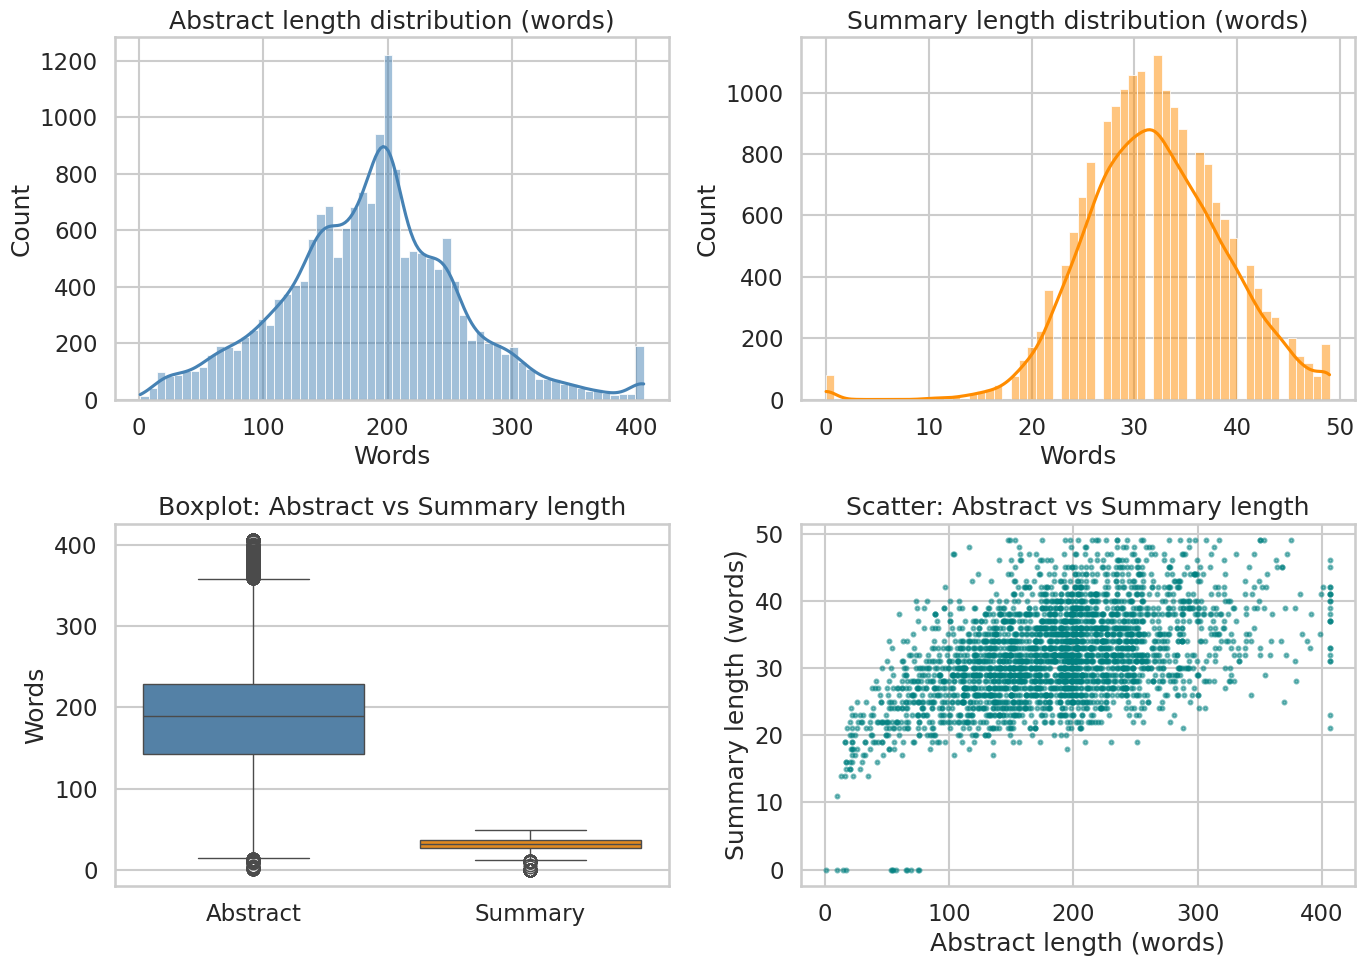

In [5]:
# ## 5. Abstract & summary length distribution (robust & richer)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ensure seaborn style
sns.set_context("talk")
sns.set_style("whitegrid")

# handle missing values safely
def safe_word_len(x):
    if isinstance(x, str):
        return len(x.split())
    return 0

df_train = df_train.copy()
df_train["abstract_len"] = df_train["abstract"].apply(safe_word_len)
df_train["summary_len"]  = df_train["summary"].apply(safe_word_len)
df_train["ratio_sum_abs"] = df_train["summary_len"] / df_train["abstract_len"].replace(0, np.nan)

# print summary stats
def describe_series(s, name):
    desc = s.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95]).to_dict()
    print(f"\n{name} (words) — stats")
    for k in ["count","mean","std","min","10%","25%","50%","75%","90%","95%","max"]:
        if k in desc:
            val = desc[k]
            print(f"  {k:>4}: {val:.2f}" if isinstance(val, (int,float)) else f"  {k:>4}: {val}")

describe_series(df_train["abstract_len"], "Abstract length")
describe_series(df_train["summary_len"],  "Summary length")
describe_series(df_train["ratio_sum_abs"].dropna(), "Summary/Abstract ratio")

# clip extreme outliers for clearer plots (e.g., 99th percentile)
abs_clip = np.percentile(df_train["abstract_len"], 99)
sum_clip = np.percentile(df_train["summary_len"], 99)

plot_abs = df_train["abstract_len"].clip(upper=abs_clip)
plot_sum = df_train["summary_len"].clip(upper=sum_clip)

# figure with multiple subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
(ax1, ax2), (ax3, ax4) = axes

# hist + kde
sns.histplot(plot_abs, bins=60, kde=True, color="steelblue", ax=ax1)
ax1.set_title("Abstract length distribution (words)")
ax1.set_xlabel("Words"); ax1.set_ylabel("Count")

sns.histplot(plot_sum, bins=60, kde=True, color="darkorange", ax=ax2)
ax2.set_title("Summary length distribution (words)")
ax2.set_xlabel("Words"); ax2.set_ylabel("Count")

# boxplots
sns.boxplot(data=[plot_abs, plot_sum], ax=ax3, palette=["steelblue","darkorange"])
ax3.set_xticklabels(["Abstract", "Summary"])
ax3.set_ylabel("Words")
ax3.set_title("Boxplot: Abstract vs Summary length")

# scatter: abstract vs summary (sample for readability)
sample = df_train.sample(min(3000, len(df_train)), random_state=42)
ax4.scatter(
    sample["abstract_len"].clip(upper=abs_clip),
    sample["summary_len"].clip(upper=sum_clip),
    s=8, alpha=0.5, color="teal"
)
ax4.set_xlabel("Abstract length (words)")
ax4.set_ylabel("Summary length (words)")
ax4.set_title("Scatter: Abstract vs Summary length")

plt.tight_layout()
plt.show()


In [6]:
# ## 6. Fields of study frequency

from collections import Counter
import itertools

fields = list(itertools.chain.from_iterable(df_train["fields_of_study"].dropna()))
Counter(fields).most_common(15)


[('Chemistry', 22784),
 ('Medicine', 19097),
 ('Biology', 6581),
 ('Materials Science', 5907),
 ('Environmental Science', 5467),
 ('Engineering', 1686),
 ('Physics', 1663),
 ('Agricultural and Food Sciences', 1106),
 ('Computer Science', 684),
 ('Mathematics', 120),
 ('Geology', 50),
 ('Education', 47),
 ('Psychology', 40),
 ('Art', 21),
 ('Business', 15)]

<Axes: xlabel='year'>

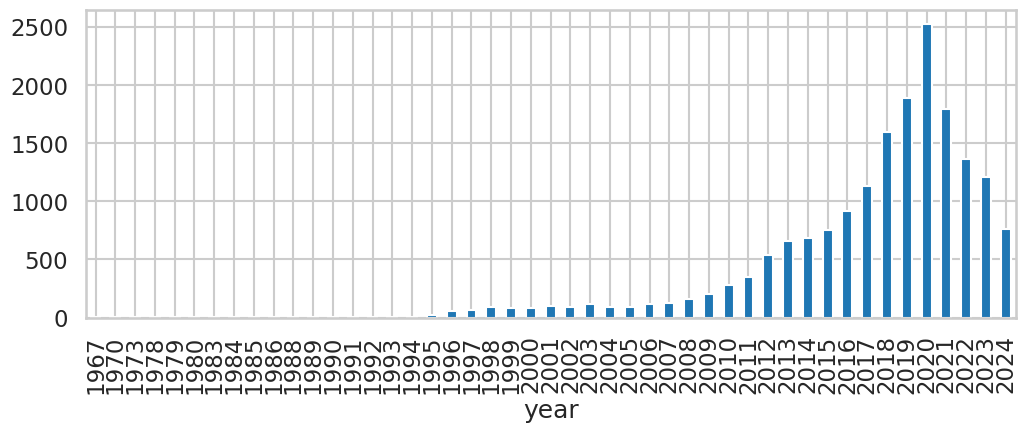

In [7]:
# ## 7. Year distribution

df_train["year"].value_counts().sort_index().plot(kind="bar", figsize=(12,4))


In [8]:
# ## 8. License check

df_train["license_type"].value_counts()


license_type
cc-by    17992
Name: count, dtype: int64

In [9]:
# ## 9. Example: Abstract → Summary pairs

for i in range(3):
    print("="*80)
    print("TITLE:", df_train.iloc[i]["title"])
    print("\nABSTRACT:\n", df_train.iloc[i]["abstract"])
    print("\nSUMMARY:\n", df_train.iloc[i]["summary"])


TITLE: Diffusion of Vanadium Ions in Artificial Saliva and Its Elimination from the Oral Cavity by Pharmacological Compounds Present in Mouthwashes

ABSTRACT:
 In this study, diffusion coefficients of ammonium vanadate at tracer concentrations in artificial saliva with and without sodium fluoride, at different pH values, were measured using an experimental model based on the Taylor dispersion technique. Ternary mutual diffusion coefficients (D11, D22, D12, and D21) for four aqueous systems {NH4VO3 (component 1) + β-cyclodextrin (β-CD) (component 2),} {NH4VO3 (component 1) + β-cyclodextrin (HP-β-CD) (component 2)}, {NH4VO3 (component 1) + sodium dodecyl sulphate (SDS) (component 2)} and {NH4VO3 (component 1) + sodium hyaluronate (NaHy) (component 2)} at 25.00 °C were also measured by using the same technique. These data showed that diffusion of ammonium vanadate was strongly affected in all aqueous media studied. Furthermore, a significant coupled diffusion of this salt and β-CD was obs

In [10]:
# ## 10. Save small sample (for quick debugging in scripts)

sample = df_train.sample(100, random_state=42)
sample.to_json("../data/samples.jsonl", orient="records", lines=True, force_ascii=False)
print("✅ Saved 100-sample dataset to ../data/samples.jsonl")


✅ Saved 100-sample dataset to ../data/samples.jsonl
